In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

In [ ]:
cb_df=pd.read_csv("/content/drive/MyDrive/cybersecurity_intrusion_data.csv")

In [ ]:
cb_df.head()

,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   object 
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   object 
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   object 
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   object 
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 819.7+ KB
None

--- Missing Values ---
session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration 

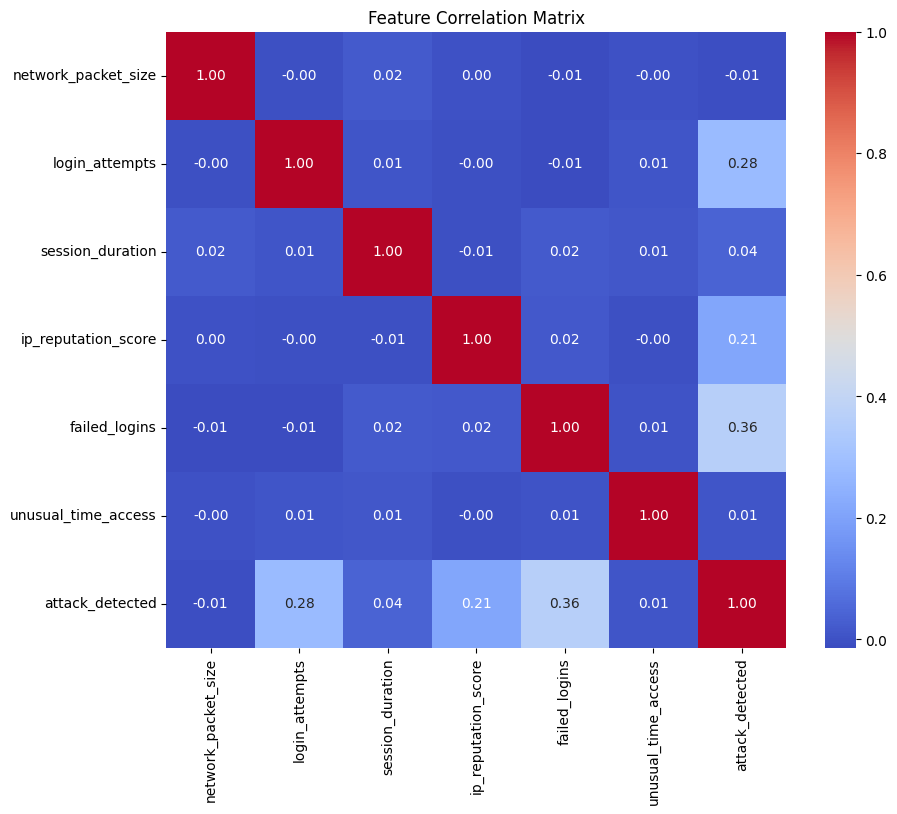

In [ ]:
print('--- Dataset Info ---')
print(cb_df.info())

print('\n--- Missing Values ---')
print(cb_df.isnull().sum())

# Check class imbalance of ground truth
print('\n--- Target Distribution (attack_detected) ---')
print(cb_df['attack_detected'].value_counts(normalize=True))

# Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cb_df.select_dtypes(include=[np.number]).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Feature Correlation Matrix')
plt.show()

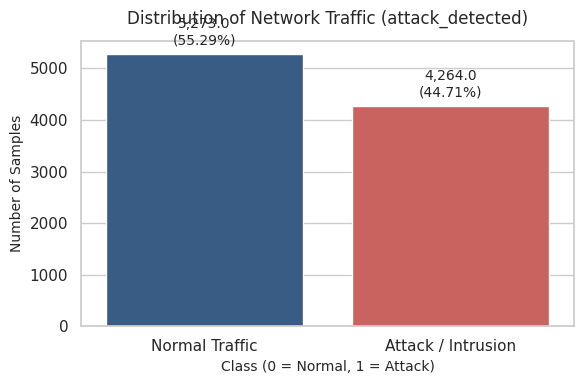

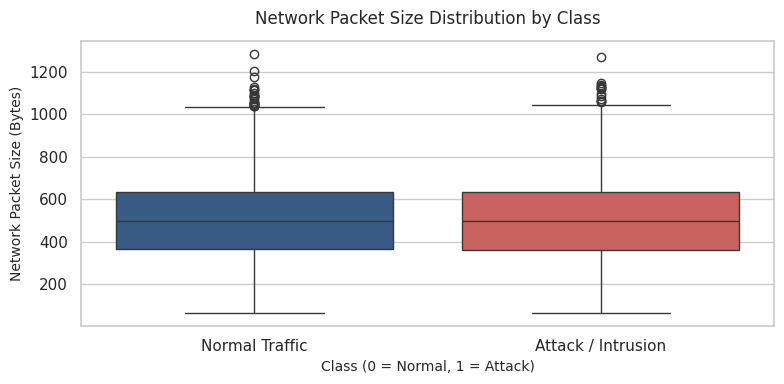

In [ ]:
sns.set_theme(style='whitegrid')

# ==========================================
# 1. COUNT PLOT FOR 'attack_detected'
# ==========================================
plt.figure(figsize=(6, 4))

# Create count plot (0: Normal, 1: Attack)
ax = sns.countplot(
    x='attack_detected',
    data=cb_df,
    palette=['#2b5c8f', '#d9534f'],  # Blue for normal, red for attack
    hue='attack_detected',
    legend=False,)


plt.title('Distribution of Network Traffic (attack_detected)', fontsize=12, pad=12)
plt.xlabel('Class (0 = Normal, 1 = Attack)', fontsize=10)
plt.ylabel('Number of Samples', fontsize=10)
plt.xticks([0, 1], ['Normal Traffic', 'Attack / Intrusion'])

# Annotate bars with exact counts and percentages
total = len(cb_df)
for p in ax.patches:
  height = p.get_height()
  percentage = f'{(height / total) * 100:.2f}%'
  ax.annotate(
      f'{height:,}\n({percentage})',
      (p.get_x() + p.get_width() / 2.0, height),
      ha='center',
      va='bottom',
      xytext=(0, 5),
      textcoords='offset points',
      fontsize=10,
  )

plt.tight_layout()
plt.show()

# ==========================================
# 2. BIVARIATE KDE / BOX PLOT (Feature vs Target)
# ==========================================
# Useful to see how a continuous feature (e.g., network_packet_size) differs between normal and attack classes
plt.figure(figsize=(8, 4))
sns.boxplot(
    x='attack_detected',
    y='network_packet_size',
    data=cb_df,
    palette=['#2b5c8f', '#d9534f'],
    hue='attack_detected',
    legend=False,
)

plt.title('Network Packet Size Distribution by Class', fontsize=12, pad=12)
plt.xlabel('Class (0 = Normal, 1 = Attack)', fontsize=10)
plt.ylabel('Network Packet Size (Bytes)', fontsize=10)
plt.xticks([0, 1], ['Normal Traffic', 'Attack / Intrusion'])

plt.tight_layout()
plt.show()

In [ ]:
X = cb_df.drop(columns=['attack_detected'])
y =cb_df['attack_detected']  # 1 for attack, 0 for normal

# 3. Train-Test Split (stratified to maintain class distribution)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Handle categorical features (One-Hot Encoding)
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

# 5. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6. Initialize and Train XGBoost Classifier
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
)

print('Training XGBoost model...')
xgb_model.fit(X_train_scaled, y_train)

Training XGBoost model...


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
# 7. Predict and Evaluate Text Metrics
y_pred = xgb_model.predict(X_test_scaled)
y_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

print('\n--- Evaluation Metrics ---')
print(classification_report(y_test, y_pred, target_names=['Normal', 'Attack']))

roc_auc = roc_auc_score(y_test, y_prob)
print(f'ROC-AUC Score: {roc_auc:.4f}')

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
auprc = auc(recall, precision)
print(f'AUPRC Score: {auprc:.4f}')


--- Evaluation Metrics ---
              precision    recall  f1-score   support

      Normal       0.83      0.99      0.90      1582
      Attack       0.98      0.75      0.85      1280

    accuracy                           0.88      2862
   macro avg       0.91      0.87      0.88      2862
weighted avg       0.90      0.88      0.88      2862

ROC-AUC Score: 0.8767
AUPRC Score: 0.9071


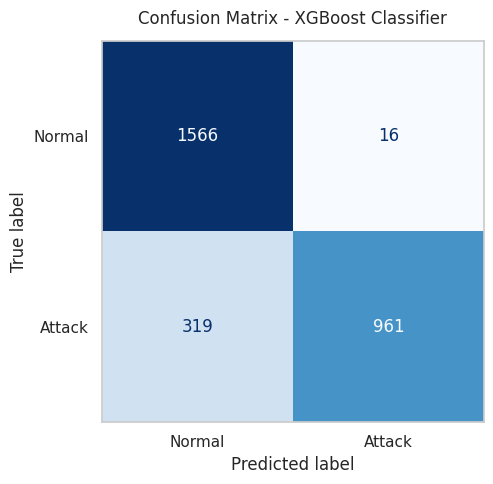

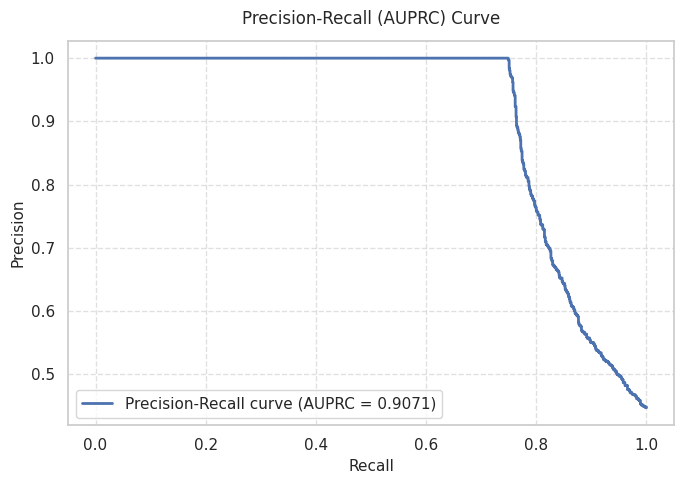

In [ ]:
# ==========================================
# 8. VISUALIZATIONS
# ==========================================

# A. Confusion Matrix Plot
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['Normal', 'Attack']
)
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca(), colorbar=False)
plt.title('Confusion Matrix - XGBoost Classifier', fontsize=12, pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

# B. Precision-Recall (AUPRC) Curve Plot
plt.figure(figsize=(7, 5))
plt.plot(
    recall,
    precision,
    color='b',
    lw=2,
    label=f'Precision-Recall curve (AUPRC = {auprc:.4f})',
)
plt.xlabel('Recall', fontsize=11)
plt.ylabel('Precision', fontsize=11)
plt.title('Precision-Recall (AUPRC) Curve', fontsize=12, pad=12)
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()